# Convert a PDF to Markdown for RAG

This recipe turns a PDF into clean Markdown and token-sized chunks you can embed in a vector store. Everything runs locally with **PyMuPDF**. There is no GPU, no cloud OCR, and no API key.

## 1. Install PyMuPDF

PyMuPDF 2.x includes the 4LLM Markdown and chunking features.

In [ ]:
%pip install -q --disable-pip-version-check pymupdf

## 2. Create a sample PDF

To keep the recipe self-contained, we generate a small two-page PDF with a heading, body text and a table. Swap in your own file by changing `pdf_path`.

In [2]:
import pymupdf

doc = pymupdf.open()

# Page 1: heading, paragraph and a ruled table
page = doc.new_page()
page.insert_htmlbox(
    pymupdf.Rect(50, 50, 545, 200),
    "<h1>Quarterly Report</h1>"
    "<p>Revenue grew <b>18%</b> year over year, driven by strong demand for document AI.</p>"
    "<h2>Regional results</h2>",
)
rows = [
    ["Region", "Revenue ($M)", "Growth"],
    ["EMEA", "42.1", "+21%"],
    ["Americas", "58.7", "+15%"],
    ["APAC", "23.4", "+19%"],
]
for r, row in enumerate(rows):
    for c, value in enumerate(row):
        cell = pymupdf.Rect(50 + c * 160, 210 + r * 24, 210 + c * 160, 234 + r * 24)
        page.draw_rect(cell, color=(0, 0, 0), width=0.8)
        page.insert_text(cell.bl + (6, -8), value, fontname="hebo" if r == 0 else "helv", fontsize=11)

# Page 2: heading and a bullet list
page = doc.new_page()
page.insert_htmlbox(
    pymupdf.Rect(50, 50, 545, 300),
    "<h2>Outlook</h2>"
    "<p>We expect continued growth as more teams build retrieval-augmented generation pipelines.</p>"
    "<ul><li>Expand partner network</li><li>Launch new SDK features</li></ul>",
)

pdf_path = "sample.pdf"
doc.save(pdf_path)
print(f"Saved {pdf_path} with {doc.page_count} pages")

Saved sample.pdf with 2 pages


## 3. Preview the first page

Render a page to an image to see what we are working with.

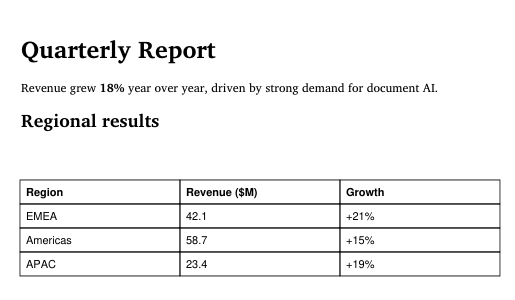

In [3]:
from IPython.display import Image

page = pymupdf.open(pdf_path)[0]
pix = page.get_pixmap(dpi=72, clip=pymupdf.Rect(30, 30, 545, 330))
Image(pix.tobytes("png"))

## 4. Convert to Markdown

`to_markdown()` keeps the document structure: headings, bold text, lists and tables. Note:  `use_ocr` is `True` by default, so we pass `use_ocr=False` as our sample is born digital.

In [4]:
doc = pymupdf.open(pdf_path)
md = doc.to_markdown(use_ocr=False)
print(md)

# **Quarterly Report** 

Revenue grew **18%** year over year, driven by strong demand for document AI. 

## **Regional results** 

|**Region**|**Revenue ($M)**|**Growth**|
|---|---|---|
|EMEA|42.1|+21%|
|Americas|58.7|+15%|
|APAC|23.4|+19%|



## **Outlook** 

We expect continued growth as more teams build retrieval-augmented generation pipelines. 

- Expand partner network 

- Launch new SDK features 




## 5. Chunk for retrieval

`to_chunks()` splits the document into token-limited chunks that respect headings and tables. Each chunk carries metadata such as page numbers and section path. There are also helpers like `to_langchain_documents()` and `to_llama_nodes()`.

In [5]:
chunks = doc.to_chunks(max_tokens=60, use_ocr=False)
print(f"{len(chunks)} chunks\n")
for chunk in chunks:
    meta = chunk.metadata
    print(f"[{chunk.id}] page {meta.page_start} · {' > '.join(meta.section_path)} · {meta.token_count} tokens")
    print(chunk.text, end="\n\n")

3 chunks

[c0] page 1 · Quarterly Report · 24 tokens
# **Quarterly Report**
Revenue grew **18%** year over year, driven by strong demand for document AI.

[c1] page 1 · Quarterly Report > Regional results · 32 tokens
## **Regional results**
|**Region**|**Revenue ($M)**|**Growth**|
|---|---|---|
|EMEA|42.1|+21%|
|Americas|58.7|+15%|
|APAC|23.4|+19%|

[c2] page 2 · Quarterly Report > Outlook · 37 tokens
## **Outlook**
We expect continued growth as more teams build retrieval-augmented generation pipelines.
- Expand partner network
- Launch new SDK features



## Next steps

- Pass the chunks to your embedding model and vector store of choice.
- Read the [PyMuPDF docs - Chunking](https://pymupdf.readthedocs.io/en/latest/chunking/index.html) for more.